## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import shap
import joblib

e:\BRM003-ML-Project\brmenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load KDDTrain+ and KDDTest+

In [2]:
train_df = pd.read_csv(r"E:\BRM003-ML-Project\dataset folder\archive\nsl-kdd\KDDTrain+.txt", header=None)
test_df = pd.read_csv(r"E:\BRM003-ML-Project\dataset folder\archive\nsl-kdd\KDDTest+.txt", header=None)

## 3. Add Column Names

In [3]:
columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "attack_type", "difficulty"
]

train_df.columns = columns
test_df.columns = columns

## 4. Dataset Overview

In [4]:
train_df.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack_type,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [5]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  str    
 2   service                      125973 non-null  str    
 3   flag                         125973 non-null  str    
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-null  int64  
 11  logged_in                    125973 non-null  int64  
 12  num_compromised              125973 non-null  int64  
 13  root_shell

In [6]:
train_df.shape

(125973, 43)

In [7]:
train_df.dtypes.value_counts()

int64      24
float64    15
str         4
Name: count, dtype: int64

## 5. Data Quality

In [8]:
train_df.isnull().sum().sort_values(ascending=False)

duration                       0
protocol_type                  0
service                        0
flag                           0
src_bytes                      0
dst_bytes                      0
land                           0
wrong_fragment                 0
urgent                         0
hot                            0
num_failed_logins              0
logged_in                      0
num_compromised                0
root_shell                     0
su_attempted                   0
num_root                       0
num_file_creations             0
num_shells                     0
num_access_files               0
num_outbound_cmds              0
is_host_login                  0
is_guest_login                 0
count                          0
srv_count                      0
serror_rate                    0
srv_serror_rate                0
rerror_rate                    0
srv_rerror_rate                0
same_srv_rate                  0
diff_srv_rate                  0
srv_diff_h

In [9]:
test_df.isnull().sum().sum()

np.int64(0)

In [10]:
train_df.duplicated().sum()

np.int64(0)

## 6. Exploratory Data Analysis

In [11]:
train_df["attack_type"].value_counts()

attack_type
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64

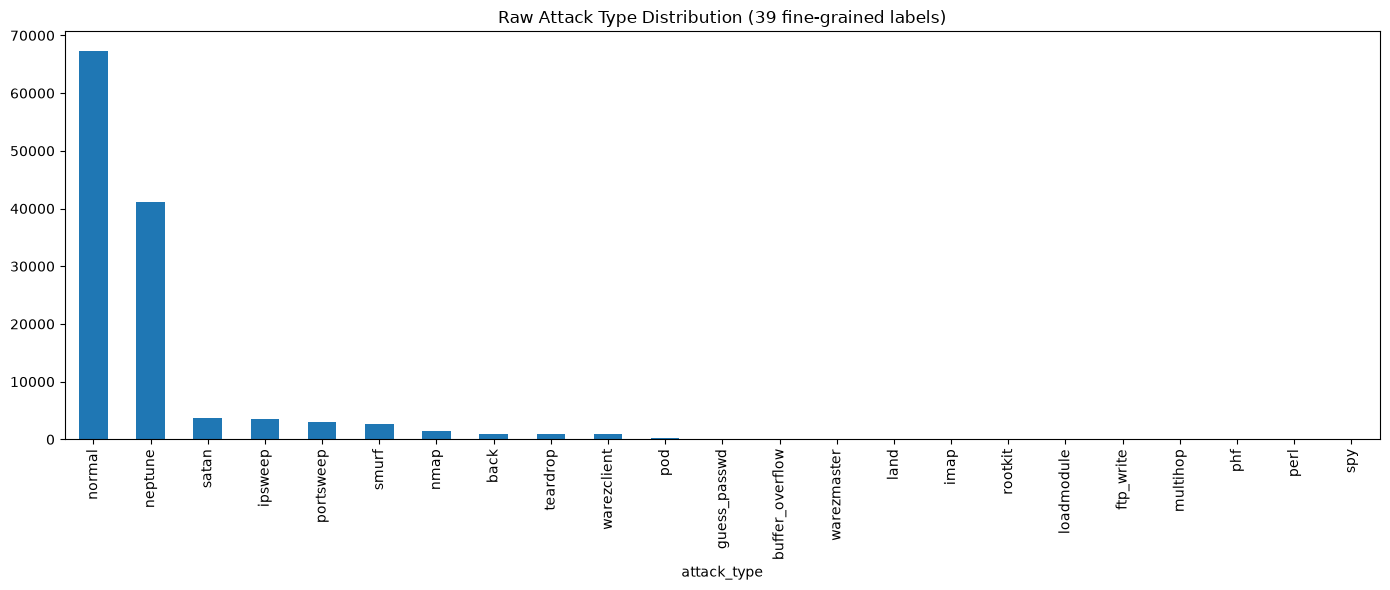

In [12]:
plt.figure(figsize=(14, 6))
train_df["attack_type"].value_counts().plot(kind="bar")
plt.title("Raw Attack Type Distribution (39 fine-grained labels)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 7. Define Target (Multiclass)

NSL-KDD's raw `attack_type` has ~39 fine-grained labels, many with only a handful of samples — far too sparse to classify directly. The standard approach (used throughout the NSL-KDD literature) is to roll every attack type up into its **attack category**:

- **Normal**
- **DoS** (Denial of Service)
- **Probe** (surveillance / scanning)
- **R2L** (Remote-to-Local)
- **U2R** (User-to-Root)

The mapping below covers every attack type that appears in KDDTrain+ and KDDTest+ (KDDTest+ contains several attack types not present in training — these are still correctly bucketed by category, which is what makes NSL-KDD a meaningful generalization test).

In [13]:
attack_category_map = {
    "normal": "Normal",

    # DoS
    "apache2": "DoS", "back": "DoS", "land": "DoS", "mailbomb": "DoS",
    "neptune": "DoS", "pod": "DoS", "processtable": "DoS", "smurf": "DoS",
    "teardrop": "DoS", "udpstorm": "DoS", "worm": "DoS",

    # Probe
    "ipsweep": "Probe", "mscan": "Probe", "nmap": "Probe",
    "portsweep": "Probe", "saint": "Probe", "satan": "Probe",

    # R2L
    "ftp_write": "R2L", "guess_passwd": "R2L", "httptunnel": "R2L",
    "imap": "R2L", "multihop": "R2L", "named": "R2L", "phf": "R2L",
    "sendmail": "R2L", "snmpgetattack": "R2L", "snmpguess": "R2L",
    "spy": "R2L", "warezclient": "R2L", "warezmaster": "R2L",
    "xlock": "R2L", "xsnoop": "R2L",

    # U2R
    "buffer_overflow": "U2R", "loadmodule": "U2R", "perl": "U2R",
    "ps": "U2R", "rootkit": "U2R", "sqlattack": "U2R", "xterm": "U2R",
}

train_df["attack_category"] = train_df["attack_type"].map(attack_category_map)
test_df["attack_category"] = test_df["attack_type"].map(attack_category_map)

# Sanity check: flag any attack_type not covered by the mapping above
unmapped_train = train_df.loc[train_df["attack_category"].isna(), "attack_type"].unique()
unmapped_test = test_df.loc[test_df["attack_category"].isna(), "attack_type"].unique()
print("Unmapped attack types in train:", unmapped_train)
print("Unmapped attack types in test:", unmapped_test)

train_df["attack_category"].value_counts()

Unmapped attack types in train: <ArrowStringArray>
[]
Length: 0, dtype: str
Unmapped attack types in test: <ArrowStringArray>
[]
Length: 0, dtype: str


attack_category
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

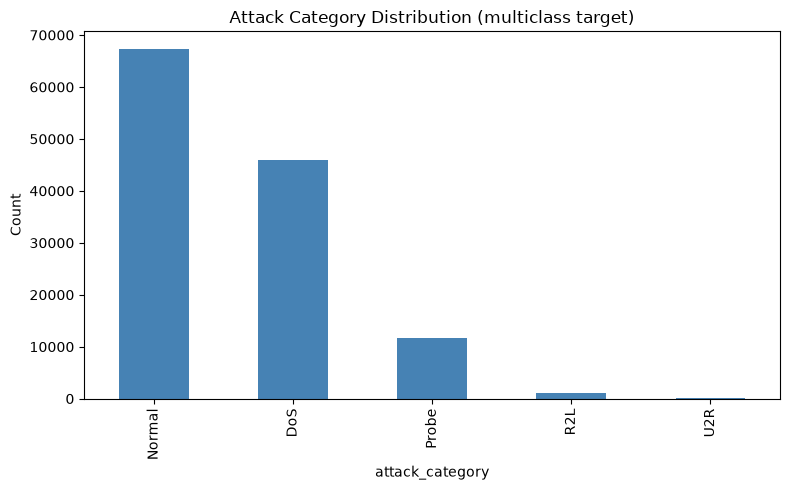

In [14]:
plt.figure(figsize=(8, 5))
train_df["attack_category"].value_counts().plot(kind="bar", color="steelblue")
plt.title("Attack Category Distribution (multiclass target)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [15]:
label_encoder = LabelEncoder()
train_df["label"] = label_encoder.fit_transform(train_df["attack_category"])
test_df["label"] = label_encoder.transform(test_df["attack_category"])

class_names = label_encoder.classes_
print("Classes:", list(enumerate(class_names)))

Classes: [(0, 'DoS'), (1, 'Normal'), (2, 'Probe'), (3, 'R2L'), (4, 'U2R')]


## 8. X / y Separation

In [16]:
X = train_df.drop(columns=["attack_type", "attack_category", "label", "difficulty"])
y = train_df["label"]

X_test_raw = test_df.drop(columns=["attack_type", "attack_category", "label", "difficulty"])
y_test = test_df["label"]

## 9. Identify Data Types

In [17]:
categorical_cols = X.select_dtypes(include=["object"]).columns
numerical_cols = X.select_dtypes(include=["int64", "float64"]).columns

print("Categorical columns:", list(categorical_cols))
print("Numerical columns:", list(numerical_cols))

Categorical columns: ['protocol_type', 'service', 'flag']
Numerical columns: ['duration', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']


C:\Users\Surya\AppData\Local\Temp\ipykernel_19504\3553609150.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=["object"]).columns


## 10. Encode Categorical Features

In [18]:
X = pd.get_dummies(X, columns=categorical_cols, drop_first=False)

# Encode the test set the same way, then align columns to the training set
X_test_raw = pd.get_dummies(X_test_raw, columns=categorical_cols, drop_first=False)
X_test_raw = X_test_raw.reindex(columns=X.columns, fill_value=0)

## 11. Train / Validation Split

In [19]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

## 12. Feature Scaling

In [20]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# Scale the held-out KDDTest+ set with the SAME scaler (fit only on training data)
X_test_scaled = scaler.transform(X_test_raw)

## 13. Handle Class Imbalance

`Normal` and `DoS` dominate; `U2R` and `R2L` are extremely rare (a handful to a few hundred samples). `SMOTE` is applied **per-class on the multiclass label**, which imblearn supports natively — it oversamples every minority class up to the majority class count (or you can pass a dict to `sampling_strategy` for finer control, e.g. leaving `Normal`/`DoS` untouched and only boosting `U2R`/`R2L`).

In [21]:
pd.Series(y_train).map(dict(enumerate(class_names))).value_counts()

label
Normal    53874
DoS       36741
Probe      9325
R2L         796
U2R          42
Name: count, dtype: int64

In [22]:
from imblearn.over_sampling import SMOTE

# U2R can have very few neighbours in the training split, so cap k_neighbors
# to avoid SMOTE errors on the rarest class
min_class_count = pd.Series(y_train).value_counts().min()
k_neighbors = max(1, min(5, min_class_count - 1))

smote = SMOTE(random_state=42, k_neighbors=k_neighbors)

X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

pd.Series(y_train_resampled).map(dict(enumerate(class_names))).value_counts()

label
DoS       53874
Normal    53874
Probe     53874
R2L       53874
U2R       53874
Name: count, dtype: int64

## 14. Baseline Models

In [23]:
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}

results = {}
fitted_models = {}

for name, clf in baseline_models.items():
    clf.fit(X_train_resampled, y_train_resampled)
    y_pred = clf.predict(X_val_scaled)

    results[name] = {
        "accuracy": accuracy_score(y_val, y_pred),
        "macro_f1": f1_score(y_val, y_pred, average="macro"),
    }
    fitted_models[name] = clf

    print(f"=== {name} ===")
    print(f"Accuracy: {results[name]['accuracy']:.4f}  |  Macro F1: {results[name]['macro_f1']:.4f}")
    print(classification_report(y_val, y_pred, target_names=class_names))

=== Logistic Regression ===
Accuracy: 0.9706  |  Macro F1: 0.7110
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00      9186
      Normal       1.00      0.95      0.97     13469
       Probe       0.93      0.98      0.96      2331
         R2L       0.33      0.93      0.49       199
         U2R       0.07      1.00      0.14        10

    accuracy                           0.97     25195
   macro avg       0.67      0.97      0.71     25195
weighted avg       0.98      0.97      0.98     25195

=== Decision Tree ===
Accuracy: 0.9979  |  Macro F1: 0.9028
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00      9186
      Normal       1.00      1.00      1.00     13469
       Probe       1.00      0.99      1.00      2331
         R2L       0.94      0.98      0.96       199
         U2R       0.47      0.70      0.56        10

    accuracy                           1.00     25195
   ma

## 15. Advanced Models (XGBoost, LightGBM)

In [24]:
advanced_models = {
    "XGBoost": XGBClassifier(
        objective="multi:softprob",
        num_class=len(class_names),
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1,
    ),
    "LightGBM": LGBMClassifier(
        objective="multiclass",
        num_class=len(class_names),
        n_estimators=200,
        max_depth=-1,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    ),
}

for name, clf in advanced_models.items():
    clf.fit(X_train_resampled, y_train_resampled)
    y_pred = clf.predict(X_val_scaled)

    results[name] = {
        "accuracy": accuracy_score(y_val, y_pred),
        "macro_f1": f1_score(y_val, y_pred, average="macro"),
    }
    fitted_models[name] = clf

    print(f"=== {name} ===")
    print(f"Accuracy: {results[name]['accuracy']:.4f}  |  Macro F1: {results[name]['macro_f1']:.4f}")
    print(classification_report(y_val, y_pred, target_names=class_names))

=== XGBoost ===
Accuracy: 0.9994  |  Macro F1: 0.9652
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00      9186
      Normal       1.00      1.00      1.00     13469
       Probe       1.00      1.00      1.00      2331
         R2L       1.00      0.99      0.99       199
         U2R       0.71      1.00      0.83        10

    accuracy                           1.00     25195
   macro avg       0.94      1.00      0.97     25195
weighted avg       1.00      1.00      1.00     25195

=== LightGBM ===
Accuracy: 0.9992  |  Macro F1: 0.9616
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00      9186
      Normal       1.00      1.00      1.00     13469
       Probe       1.00      1.00      1.00      2331
         R2L       1.00      0.98      0.99       199
         U2R       0.75      0.90      0.82        10

    accuracy                           1.00     25195
   macro avg       0.9

### Soft-Voting Ensemble (Random Forest + XGBoost + LightGBM)

In [25]:
voting_clf = VotingClassifier(
    estimators=[
        ("rf", fitted_models["Random Forest"]),
        ("xgb", fitted_models["XGBoost"]),
        ("lgbm", fitted_models["LightGBM"]),
    ],
    voting="soft",
)

voting_clf.fit(X_train_resampled, y_train_resampled)
y_pred_voting = voting_clf.predict(X_val_scaled)

results["Voting Ensemble (RF+XGB+LGBM)"] = {
    "accuracy": accuracy_score(y_val, y_pred_voting),
    "macro_f1": f1_score(y_val, y_pred_voting, average="macro"),
}
fitted_models["Voting Ensemble (RF+XGB+LGBM)"] = voting_clf

print("=== Voting Ensemble (RF + XGBoost + LightGBM) ===")
print(classification_report(y_val, y_pred_voting, target_names=class_names))

=== Voting Ensemble (RF + XGBoost + LightGBM) ===
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00      9186
      Normal       1.00      1.00      1.00     13469
       Probe       1.00      1.00      1.00      2331
         R2L       1.00      0.98      0.99       199
         U2R       0.77      1.00      0.87        10

    accuracy                           1.00     25195
   macro avg       0.95      1.00      0.97     25195
weighted avg       1.00      1.00      1.00     25195



In [26]:
pd.DataFrame(results).T.sort_values("macro_f1", ascending=False)

,accuracy,macro_f1
Voting Ensemble (RF+XGB+LGBM),0.999405,0.972025
Random Forest,0.999008,0.966201
XGBoost,0.999365,0.965205
LightGBM,0.999246,0.961622
Decision Tree,0.997936,0.902819
Logistic Regression,0.970629,0.710964


## 16. Hyperparameter Tuning

`RandomizedSearchCV` on Random Forest, scored on **macro F1** (not accuracy) so the tiny `U2R`/`R2L` classes actually influence the search — with plain accuracy the search would just optimize for `Normal`/`DoS`.

In [27]:
param_dist = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=10,
    scoring="f1_macro",
    cv=3,
    random_state=42,
    n_jobs=-1,
)

rf_search.fit(X_train_resampled, y_train_resampled)

print("Best params:", rf_search.best_params_)
print("Best CV macro F1:", rf_search.best_score_)

best_rf = rf_search.best_estimator_
fitted_models["Random Forest (tuned)"] = best_rf

Best params: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_depth': 30}
Best CV macro F1: 0.999647330890534


## 17. Feature Importance

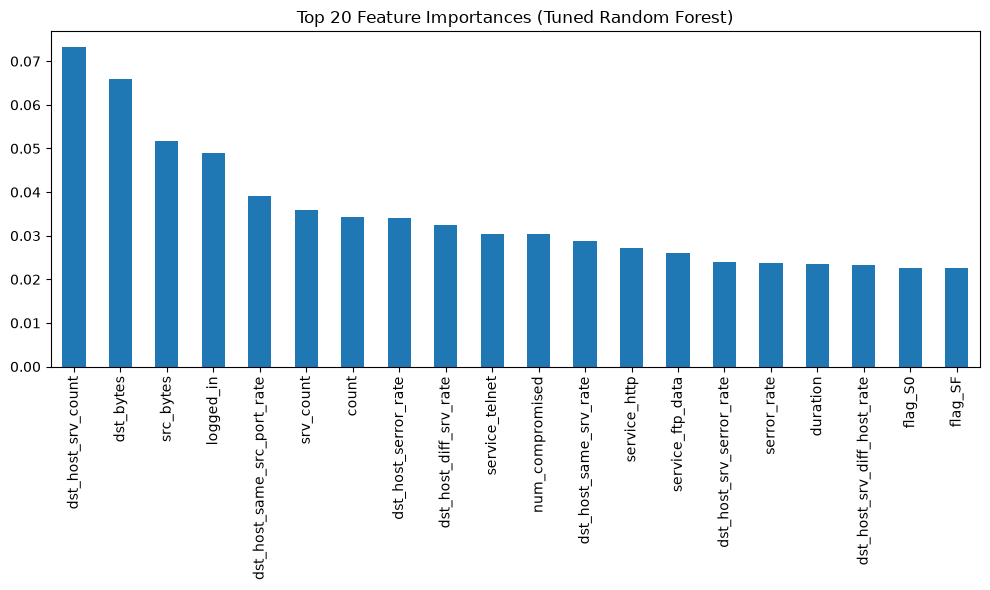

In [28]:
importance = pd.Series(
    best_rf.feature_importances_,
    index=X_train.columns
)

importance.sort_values(ascending=False).head(20).plot(
    kind="bar",
    figsize=(10, 6),
    title="Top 20 Feature Importances (Tuned Random Forest)"
)

plt.tight_layout()
plt.show()

## 18. SHAP Explainability (Multiclass)

`TreeExplainer` on the tuned Random Forest returns one set of SHAP values **per class**. The cell below plots the summary for a single class at a time — change `class_to_explain` to inspect any of the five categories (e.g. `"U2R"` or `"R2L"` are usually the most interesting, since that's where minority-class detection is hardest).

SHAP summary for class: U2R


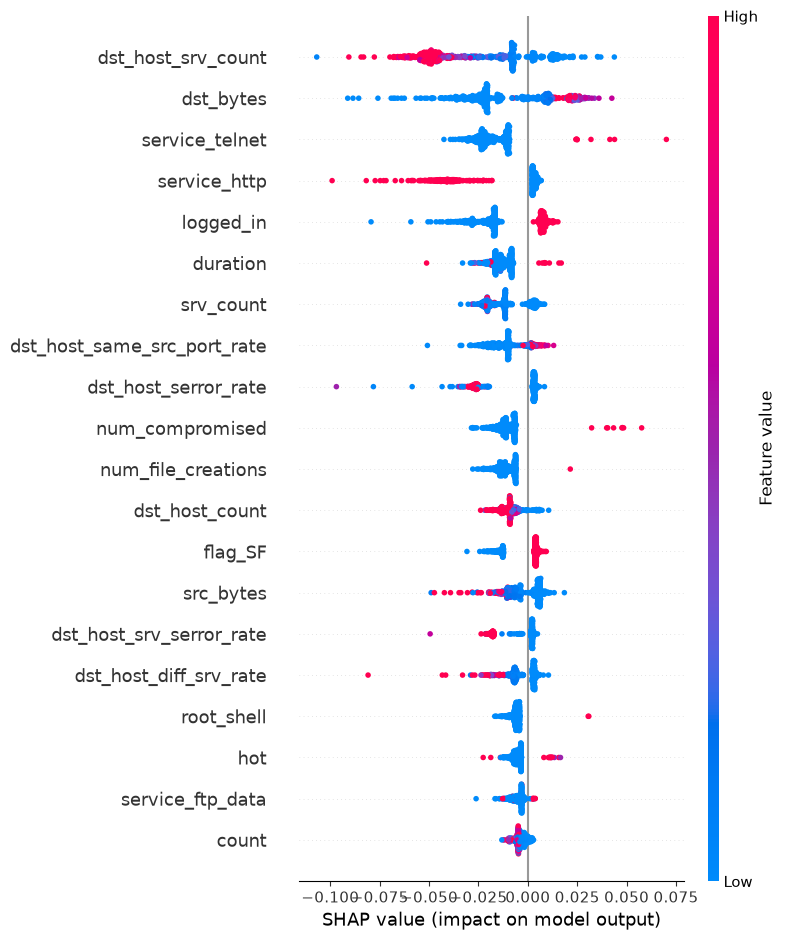

In [29]:
explainer = shap.TreeExplainer(best_rf)

shap_sample_df = pd.DataFrame(X_val_scaled, columns=X_train.columns).sample(
    n=min(500, len(X_val)), random_state=42
)

shap_values = explainer.shap_values(shap_sample_df)

class_to_explain = "U2R"
class_idx = list(class_names).index(class_to_explain)

# Handle both SHAP API shapes: list-of-arrays (legacy) or a single 3D array (samples, features, classes)
if isinstance(shap_values, list):
    sv_for_class = shap_values[class_idx]
else:
    sv_for_class = shap_values[:, :, class_idx]

print(f"SHAP summary for class: {class_to_explain}")
shap.summary_plot(sv_for_class, shap_sample_df, show=True)

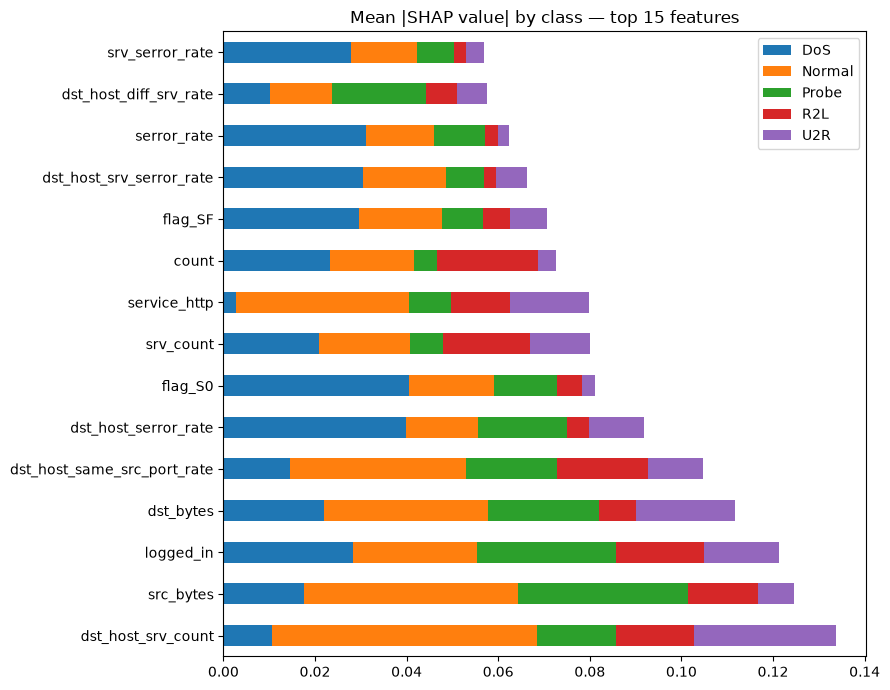

In [30]:
# Mean |SHAP value| per class, for the top features — a compact multiclass overview
mean_abs_shap = {}
for i, cname in enumerate(class_names):
    sv_i = shap_values[i] if isinstance(shap_values, list) else shap_values[:, :, i]
    mean_abs_shap[cname] = np.abs(sv_i).mean(axis=0)

shap_overview = pd.DataFrame(mean_abs_shap, index=X_train.columns)
top_features = shap_overview.sum(axis=1).sort_values(ascending=False).head(15).index

shap_overview.loc[top_features].plot(
    kind="barh", stacked=True, figsize=(9, 7),
    title="Mean |SHAP value| by class — top 15 features"
)
plt.tight_layout()
plt.show()

## 19. Model Evaluation

In [31]:
best_model_name = pd.DataFrame(results).T["macro_f1"].idxmax()
best_model = fitted_models[best_model_name]
print("Best model on validation set (by macro F1):", best_model_name)

y_pred_best = best_model.predict(X_val_scaled)

print(classification_report(y_val, y_pred_best, target_names=class_names))

Best model on validation set (by macro F1): Voting Ensemble (RF+XGB+LGBM)
              precision    recall  f1-score   support

         DoS       1.00      1.00      1.00      9186
      Normal       1.00      1.00      1.00     13469
       Probe       1.00      1.00      1.00      2331
         R2L       1.00      0.98      0.99       199
         U2R       0.77      1.00      0.87        10

    accuracy                           1.00     25195
   macro avg       0.95      1.00      0.97     25195
weighted avg       1.00      1.00      1.00     25195



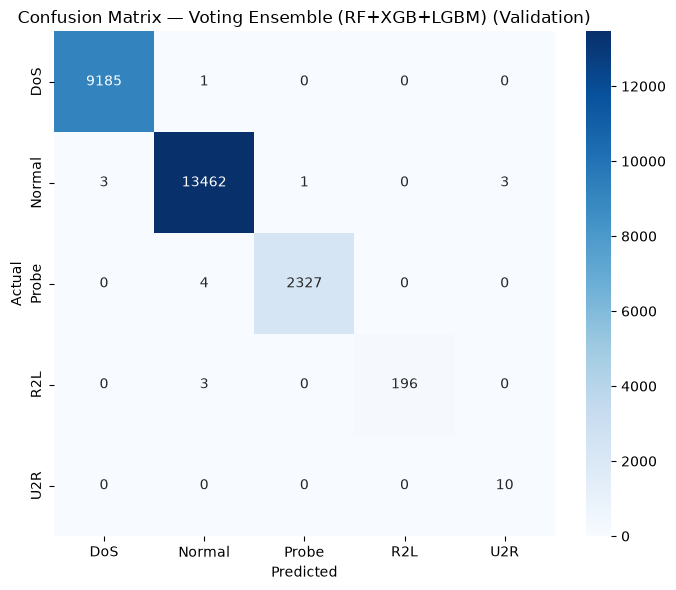

In [32]:
cm = confusion_matrix(y_val, y_pred_best)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix — {best_model_name} (Validation)")
plt.tight_layout()
plt.show()

In [33]:
prob_val = best_model.predict_proba(X_val_scaled)
auc_val_macro = roc_auc_score(y_val, prob_val, multi_class="ovr", average="macro")
print("Validation macro ROC-AUC (one-vs-rest):", auc_val_macro)

Validation macro ROC-AUC (one-vs-rest): 0.9999897709003683


## 20. Final Evaluation on KDDTest+

Note: KDDTest+ contains attack types not seen in KDDTrain+ (still correctly bucketed by category via the mapping in Step 7), which is exactly why NSL-KDD multiclass results are typically noticeably lower on the test set than on the validation split — it's a genuine generalization test, not a bug.

In [34]:
y_pred_test = best_model.predict(X_test_scaled)
prob_test = best_model.predict_proba(X_test_scaled)

print(f"=== {best_model_name} — KDDTest+ (held-out) ===")
print(classification_report(y_test, y_pred_test, target_names=class_names))

auc_test_macro = roc_auc_score(y_test, prob_test, multi_class="ovr", average="macro")
print("Test macro ROC-AUC (one-vs-rest):", auc_test_macro)

=== Voting Ensemble (RF+XGB+LGBM) — KDDTest+ (held-out) ===
              precision    recall  f1-score   support

         DoS       0.96      0.83      0.89      7460
      Normal       0.69      0.97      0.81      9711
       Probe       0.85      0.69      0.76      2421
         R2L       0.98      0.13      0.23      2885
         U2R       0.71      0.30      0.42        67

    accuracy                           0.79     22544
   macro avg       0.84      0.58      0.62     22544
weighted avg       0.83      0.79      0.75     22544

Test macro ROC-AUC (one-vs-rest): 0.9467471927991149


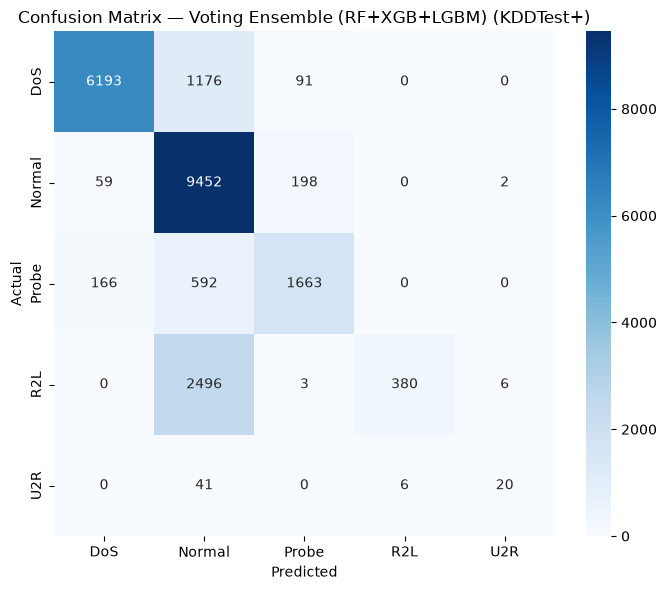

In [35]:
cm_test = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix — {best_model_name} (KDDTest+)")
plt.tight_layout()
plt.show()

## 21. Save Model

In [36]:
joblib.dump(best_model, "best_model_multiclass.joblib")
joblib.dump(scaler, "scaler_multiclass.joblib")
joblib.dump(list(X_train.columns), "feature_columns_multiclass.joblib")
joblib.dump(label_encoder, "label_encoder_multiclass.joblib")

print(f"Saved '{best_model_name}' to best_model_multiclass.joblib, plus scaler, feature columns, and label encoder")

Saved 'Voting Ensemble (RF+XGB+LGBM)' to best_model_multiclass.joblib, plus scaler, feature columns, and label encoder
